# Demo 2｜城市灰度上线的双重差分评估

决策问题：派单策略是否缩短接驾时长？估计处理城市上线后的 ATT。核心假设是若未上线，处理与对照城市的走势可比。

**数据声明**：以下均为固定随机种子生成的模拟数据，不代表真实滴滴业务效果。图中的英文标签用于避免本地中文字体依赖。

## 城市周面板与数据字典

`city` 城市；`week` 周；`treated` 是否处理城市；`post` 是否上线后；`wait` 平均接驾分钟。12 城市、24 周，其中 4 城市在第 12 周上线。模拟公共季节性、城市基线和噪声。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')
rng = np.random.default_rng(20261028)
import statsmodels.formula.api as smf
cities=np.arange(12);weeks=np.arange(24);rows=[]
city_base=rng.normal(0,.4,12)
for c in cities:
 for w in weeks:
  tr=int(c<4);post=int(w>=12)
  y=8+city_base[c]+.025*w+.25*np.sin(w/3)-.55*tr*post+rng.normal(0,.16)
  rows.append((c,w,tr,post,y))
df=pd.DataFrame(rows,columns=['city','week','treated','post','wait'])
print(df.head())

   city  week  treated  post      wait
0     0     0        1     0  7.784229
1     0     1        1     0  8.138336
2     0     2        1     0  8.255596
3     0     3        1     0  8.304773
4     0     4        1     0  8.320266


## 趋势图与前趋势诊断

先看处理与对照组上线前走势，不能只看回归系数。模拟数据的平行趋势是由生成机制设定的；真实数据必须额外论证同期冲击。

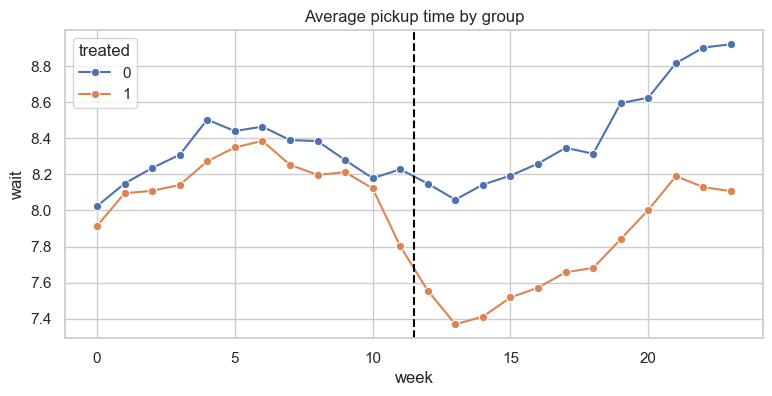

Pretrend differential slope: -0.010100432024906287 p= 0.062492894280393396


In [2]:
trend=df.groupby(['week','treated']).wait.mean().reset_index()
plt.figure(figsize=(9,4));sns.lineplot(data=trend,x='week',y='wait',hue='treated',marker='o');plt.axvline(11.5,color='black',ls='--');plt.title('Average pickup time by group');plt.show()
pre=df[df.week<12].copy();pre['time_trend']=pre.week*pre.treated
pre_fit=smf.ols('wait ~ C(city)+C(week)+time_trend',data=pre).fit(cov_type='cluster',cov_kwds={'groups':pre.city})
print('Pretrend differential slope:',pre_fit.params['time_trend'],'p=',pre_fit.pvalues['time_trend'])

## 双重差分估计

城市与周固定效应控制稳定城市差异与共同时间冲击；城市聚类标准误考虑城市内相关。但 12 个城市簇偏少，常规聚类区间可能偏乐观，真实研究应考虑更多簇、随机化推断或野生聚类 bootstrap。

DiD ATT: -0.5462317310127354 95% CI: [-0.620585081813165, -0.47187838021230577] p: 5.269592214480127e-47
post            0         1
treated                    
0        8.298773  8.443794
1        8.154532  7.753321


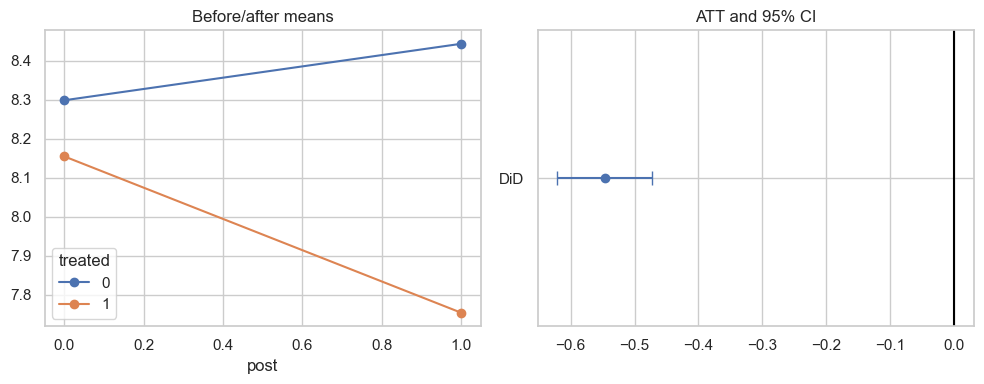

In [3]:
df['did']=df.treated*df.post
fit=smf.ols('wait ~ did + C(city)+C(week)',data=df).fit(cov_type='cluster',cov_kwds={'groups':df.city})
print('DiD ATT:',fit.params['did'],'95% CI:',fit.conf_int().loc['did'].tolist(),'p:',fit.pvalues['did'])
summary=df.groupby(['treated','post']).wait.mean().unstack();print(summary)
fig,ax=plt.subplots(1,2,figsize=(10,4));summary.T.plot(marker='o',ax=ax[0]);ax[0].set_title('Before/after means');ax[1].errorbar(fit.params['did'],0,xerr=1.96*fit.bse['did'],fmt='o',capsize=5);ax[1].axvline(0,color='black');ax[1].set_yticks([0],['DiD']);ax[1].set_title('ATT and 95% CI');plt.tight_layout();plt.show()

## 事件研究、安慰剂与敏感性

以第 11 周为参照，用每周处理组交互项展示动态效应。上线前的伪时间点应无系统效果；改用不同对照城市检查稳定性。

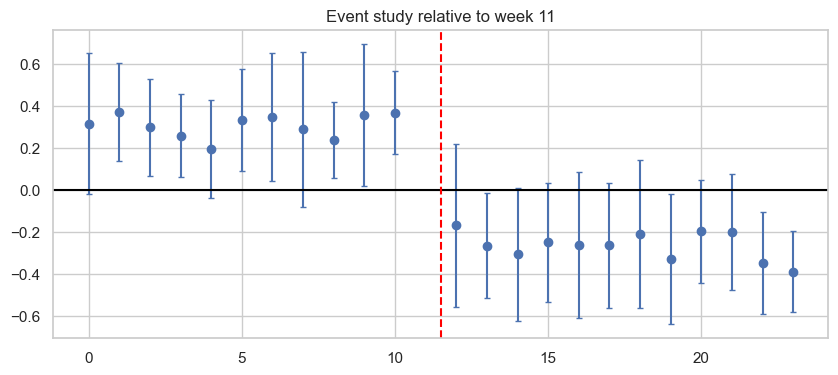

Placebo: -0.02885927857898825 0.48017777136415496
Controls [4, 5, 6, 7] ATT -0.599
Controls [8, 9, 10, 11] ATT -0.494
Decision: simulated reduction only; actual causal claim requires credible city comparability and shock audit.


In [4]:
df['rel']=df.week-12
for w in weeks:
 if w!=11:df[f'e{w}']=((df.week==w)&(df.treated==1)).astype(int)
terms=' + '.join(f'e{w}' for w in weeks if w!=11)
es=smf.ols('wait ~ C(city)+C(week)+'+terms,data=df).fit(cov_type='cluster',cov_kwds={'groups':df.city})
coef=pd.DataFrame({'week':[w for w in weeks if w!=11],'estimate':[es.params[f'e{w}'] for w in weeks if w!=11],'se':[es.bse[f'e{w}'] for w in weeks if w!=11]})
plt.figure(figsize=(10,4));plt.errorbar(coef.week,coef.estimate,yerr=1.96*coef.se,fmt='o',capsize=2);plt.axhline(0,color='black');plt.axvline(11.5,color='red',ls='--');plt.title('Event study relative to week 11');plt.show()
pre=df[df.week<12].copy();pre['fake']=(pre.week>=6)*pre.treated
placebo=smf.ols('wait ~ fake+C(city)+C(week)',data=pre).fit(cov_type='cluster',cov_kwds={'groups':pre.city})
print('Placebo:',placebo.params['fake'],placebo.pvalues['fake'])
for controls in ([4,5,6,7],[8,9,10,11]):
 d=df[(df.treated==1)|df.city.isin(controls)]
 m=smf.ols('wait ~ did+C(city)+C(week)',data=d).fit(cov_type='cluster',cov_kwds={'groups':d.city})
 print('Controls',controls,'ATT',round(m.params['did'],3))
print('Decision: simulated reduction only; actual causal claim requires credible city comparability and shock audit.')

## 模拟结果解读与决策摘要

- 处理城市的模拟接驾时长在上线前后下降，对照城市同期略上升。双重差分约 **-0.546 分钟**，常规城市聚类 95% 区间约 **[-0.621,-0.472]**。
- 前趋势差异斜率检验 p≈0.062，未达到常用 0.05 阈值，但这**不能证明**平行趋势成立；事件研究图和业务冲击排查仍重要。
- 伪上线时间的估计约 -0.029 分钟，p≈0.48。更换对照城市后点估计约 -0.599 与 -0.494 分钟，方向稳定但幅度变化。
- 只有 12 个城市簇，常规聚类标准误的推断可能过于乐观。真实项目应扩大城市样本或采用适合少簇情形的推断，并核查政策、天气及供需同期冲击。


## 实证分析接入

当前目录没有可用于此案例的真实数据，故不把模拟结论解释为实际业务结论。接入真实数据时：①取得脱敏且获授权的数据；②核对数据字典、随机化/触达机制和时间窗；③用真实数据替换模拟数据生成单元；④重跑质量诊断与敏感性分析；⑤在审阅关键识别假设后更新决策摘要。